# Loan Default Scorecard — End-to-End Pipeline (v0.2)
**Split → Leakage screen → Cleaning → EDA → Binning & IV → Variable selection → Modelling → Evaluation**

Dataset: `Loan_Default.csv` (148,670 records, 2019 vintage). Target `Status` (1 = default, 0 = non-default), base rate ≈ 24.6%.

**What changed from v0.1 (following `AUDIT.md`):**

| Audit finding | v0.2 change |
|---|---|
| C1/C2: label encoded by blank fields; leak re-entered through mean-imputed LTV/dtir1 | Data-driven label-proxy scan; records with blank-field proxies are excluded from the scored population instead of being imputed; no mean imputation anywhere |
| C3: unreproducible "≈0.74" | Every figure is computed in this notebook, with bootstrap CIs |
| H1: preprocessing fit on full data | Split happens **first**; every target-aware step (leak scan, bins, WoE, IV, selection) uses train only |
| H2: reversed coefficient signs | Forward selection only accepts a feature if every coefficient stays negative (WoE convention) |
| H3: `loan_type` ≡ `business_or_commercial` | Correlation screen on WoE features drops the lower-IV member of any pair with \|r\| > 0.7; a shared-blank check stops `income`/`dtir1` counting the same blank records twice |
| M1: biased row drops | No rows dropped for blank categoricals: blanks become an explicit `MISSING` category |
| M3: unused validation set | The validation set drives variable selection; the test set is touched only once |
| M4: no uncertainty | 95% bootstrap CIs on AUC, Gini and KS |

> **Caveat carried through the whole notebook (audit C1):** even after the remediation, `Status` in the scored
> population matches "`rate_of_interest` is blank" exactly (§3.3). What this model ranks may be a data-collection
> artifact rather than credit risk. The pipeline is a sound *method*; this dataset cannot *validate* a credit model.

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
RANDOM_STATE = 42

# Works when run from notebooks/, from the project root, or next to the CSV
DATA_PATH = next(p for p in ['../data/Loan_Default.csv', 'data/Loan_Default.csv', 'Loan_Default.csv']
                 if os.path.exists(p))
print('data:', DATA_PATH)

data: ../data/Loan_Default.csv


## 1. Load & First Look
`ID` is a sequential row number and `year` is constant (2019). Neither is a usable characteristic.

In [2]:
df = pd.read_csv(DATA_PATH)
print('shape:', df.shape, '| years:', df['year'].unique())
print('target balance:', df['Status'].value_counts(normalize=True).round(3).to_dict())
df = df.drop(columns=['ID', 'year'])
miss = (df.isna().mean() * 100).round(2)
miss[miss > 0].sort_values(ascending=False)

shape: (148670, 34) | years: [2019]
target balance: {0: 0.754, 1: 0.246}


Upfront_charges              26.66
Interest_rate_spread         24.64
rate_of_interest             24.51
dtir1                        16.22
property_value               10.16
LTV                          10.16
income                        6.15
loan_limit                    2.25
approv_in_adv                 0.61
submission_of_application     0.13
age                           0.13
loan_purpose                  0.09
Neg_ammortization             0.08
term                          0.03
dtype: float64

## 2. Train / Validation / Test Split (stratified 60/20/20) — done FIRST

**Why first?** v0.1 imputed, winsorised and ran the IV screen on the full dataset before splitting, so the test
set helped choose the features (audit H1). Here the split comes before anything that looks at the target. From
now on every data-driven decision is fitted on **train**, the **validation** set is used to choose variables, and
**test** is used once, at the end.

A time-based split is impossible: every record is from 2019 and there is no finer date.

In [3]:
train, tmp = train_test_split(df, test_size=0.40, stratify=df['Status'], random_state=RANDOM_STATE)
val, test = train_test_split(tmp, test_size=0.50, stratify=tmp['Status'], random_state=RANDOM_STATE)
for nm, d in [('train', train), ('val', val), ('test', test)]:
    print(f'{nm:5s} n={len(d):6d} default_rate={d.Status.mean():.4f}')

train n= 89202 default_rate=0.2464
val   n= 29734 default_rate=0.2465
test  n= 29734 default_rate=0.2465


## 3. Leakage Screen (train only)

### 3.1 Label-proxy scan
v0.1 found its leaks one at a time, by eye. Here the check is systematic. For every column we compute the
default rate when the value is **missing**, when it is **present**, and for every **category**. Any group of at
least 30 train records with a default rate ≥ 99% or ≤ 1% is flagged. Genuine borrower characteristics do not
produce near-certain outcomes. Data-collection artifacts do.

In [4]:
def proxy_scan(d, target='Status', lo=0.01, hi=0.99, min_n=30):
    rows = []
    def check(col, group, mask):
        n = int(mask.sum())
        if n >= min_n:
            r = d.loc[mask, target].mean()
            if r <= lo or r >= hi:
                rows.append({'column': col, 'group': group, 'n': n, 'default_rate': round(r, 4)})
    for c in d.columns.drop(target):
        m = d[c].isna()
        if m.any():
            check(c, '<missing>', m)
            check(c, '<present>', ~m)
        if not pd.api.types.is_numeric_dtype(d[c]):
            for k in d[c].dropna().unique():
                check(c, k, d[c] == k)
    return pd.DataFrame(rows, columns=['column', 'group', 'n', 'default_rate'])

proxy_scan(train)

,column,group,n,default_rate
0,rate_of_interest,<missing>,21870,1.0000
1,rate_of_interest,<present>,67332,0.0017
2,Interest_rate_spread,<missing>,21983,1.0000
3,Interest_rate_spread,<present>,67219,0.0000
4,Upfront_charges,<present>,65398,0.0013
5,property_value,<missing>,9091,1.0000
6,credit_type,EQUI,9204,1.0000
7,age,<missing>,113,1.0000
8,submission_of_application,<missing>,113,1.0000
9,LTV,<missing>,9091,1.0000


### 3.2 Remediation decisions

| Flag | Decision | Rationale |
|---|---|---|
| `rate_of_interest`, `Interest_rate_spread`, `Upfront_charges` (missing ⇒ ~100% default, present ⇒ ~0%) | **Drop the columns** | Pricing fields whose presence encodes the label |
| `property_value` / `LTV` missing (100% default) | **Exclude the records** from the scored population | v0.1 kept them in a `MISSING` bin (−194 pts) and mean-imputed LTV/dtir1, which copied the leak into those features (audit C2) |
| `age` / `submission_of_application` missing (100% default) | **Exclude the records** | Same kind of proxy. v0.1 removed these rows only as a side effect of `dropna` |
| `credit_type == 'EQUI'` (≈100% default) | **Exclude the records** | Label proxy. With EQUI gone, `credit_type` is free to go through the normal IV screen |

**Production reading:** an application with any of these fields blank, or bureau = EQUI, is routed to manual
review. The scorecard covers only complete applications. The same rules are applied unchanged to all three
partitions.

In [5]:
LEAK_COLS = ['rate_of_interest', 'Interest_rate_spread', 'Upfront_charges']

def in_scope(d):
    return (d['property_value'].notna() & d['age'].notna()
            & d['submission_of_application'].notna() & (d['credit_type'] != 'EQUI'))

# keep the rate-missing flag aside purely as a diagnostic (never a feature)
rate_blank = {nm: d.loc[in_scope(d), 'rate_of_interest'].isna()
              for nm, d in [('train', train), ('val', val), ('test', test)]}

parts = {}
for nm, d in [('train', train), ('val', val), ('test', test)]:
    s = d.loc[in_scope(d)].drop(columns=LEAK_COLS)
    parts[nm] = s
    print(f'{nm:5s} kept {len(s):6d} of {len(d):6d} ({len(s)/len(d):.1%})  default_rate={s.Status.mean():.4f}')
train_s, val_s, test_s = parts['train'], parts['val'], parts['test']

print('\nre-scan of in-scope train (should be empty):')
proxy_scan(train_s)

train kept  79998 of  89202 (89.7%)  default_rate=0.1597
val   kept  26721 of  29734 (89.9%)  default_rate=0.1616
test  kept  26651 of  29734 (89.6%)  default_rate=0.1593

re-scan of in-scope train (should be empty):


,column,group,n,default_rate


### 3.3 Residual caveat — what the target still means (audit C1)
The scan above comes back clean, but one fact remains. In the in-scope population, **every** default has a blank
`rate_of_interest` and **no** non-default does. The rate columns are no longer features, but the label may still
be recording "pricing was never filled in" rather than "the borrower failed to pay". Nothing at record level can
fix this. It limits what the evaluation below can claim.

In [6]:
print(pd.crosstab(train_s['Status'], rate_blank['train'].rename('rate_of_interest blank')))
print('corr(Status, rate blank) in scope — train: %.4f | test: %.4f' % (
    np.corrcoef(train_s.Status, rate_blank['train'])[0, 1],
    np.corrcoef(test_s.Status, rate_blank['test'])[0, 1]))

rate_of_interest blank  False  True 
Status                              
0                       67219      0
1                           0  12779
corr(Status, rate blank) in scope — train: 1.0000 | test: 1.0000


## 4. Cleaning

- **LTV decimal errors.** Values > 150 are divided by 100 (e.g. 7831 → 78.31). This is a fixed rule with nothing
  fitted, so it is safe to apply to every partition.
- **No imputation.** A missing `income` or `dtir1` becomes its own `MISSING` bin, so its real effect stays
  visible. Mean imputation created the spikes that carried the leak in v0.1.
- **No row drops.** A blank categorical becomes the category `MISSING` (v0.1's `dropna` removed rows with a
  29% default rate).
- **No winsorising.** Capping is a monotone transform, so it cannot change which quantile bin a value falls in.
  For a binned WoE model it is a no-op, and dropping it removes one more step that v0.1 fitted on the full data.
- `term` has only a handful of distinct values, so it is treated as categorical.

In [7]:
def clean(d):
    d = d.copy()
    d.loc[d['LTV'] > 150, 'LTV'] = d.loc[d['LTV'] > 150, 'LTV'] / 100
    d['term'] = d['term'].astype('Int64').astype(str).replace('<NA>', np.nan)
    return d

train_s, val_s, test_s = clean(train_s), clean(val_s), clean(test_s)
y_tr, y_va, y_te = train_s.pop('Status'), val_s.pop('Status'), test_s.pop('Status')
print('LTV range (train):', round(train_s.LTV.min(), 2), '-', round(train_s.LTV.max(), 2))
print('remaining missingness (train, %):')
m = (train_s.isna().mean() * 100).round(2); print(m[m > 0].sort_values(ascending=False).to_string())

LTV range (train): 1.52 - 149.64
remaining missingness (train, %):
income               6.78
dtir1                6.69
loan_limit           2.22
approv_in_adv        0.62
Neg_ammortization    0.09
loan_purpose         0.08
term                 0.02


## 5. Exploratory Data Analysis (train, in scope)

In [8]:
eda = train_s.assign(Status=y_tr)
for col in ['Credit_Worthiness', 'loan_purpose', 'term', 'credit_type']:
    g = eda.groupby(col, dropna=False)['Status'].agg(['mean', 'count'])
    g = g[g['count'] >= 100]; g['mean'] = (g['mean'] * 100).round(1)
    print(f'\n[{col} — default rate %]'); print(g.sort_values('mean', ascending=False).to_string())
print('\n[Credit_Score deciles — default rate %]')
print((eda.groupby(pd.qcut(eda.Credit_Score, 10))['Status'].mean() * 100).round(1).values)


[Credit_Worthiness — default rate %]
                   mean  count
Credit_Worthiness             
l2                 21.0   3332
l1                 15.8  76666

[loan_purpose — default rate %]
              mean  count
loan_purpose             
p2            24.3   1763
p3            17.7  30622
p1            14.7  17913
p4            14.4  29635

[term — default rate %]
      mean  count
term             
300   44.2   1323
180   15.9   7050
360   15.7  65656
324   15.3   1442
240   12.3   3145
348   11.6    146
144   10.7    140
120    9.5    264
96     8.6    105
336    8.0    112
312    7.3    110

[credit_type — default rate %]
             mean  count
credit_type             
CRIF         16.4  26311
EXP          15.8  24829
CIB          15.7  28858

[Credit_Score deciles — default rate %]
[15.8 16.1 16.5 15.9 15.9 15.1 15.3 16.1 16.3 16.7]


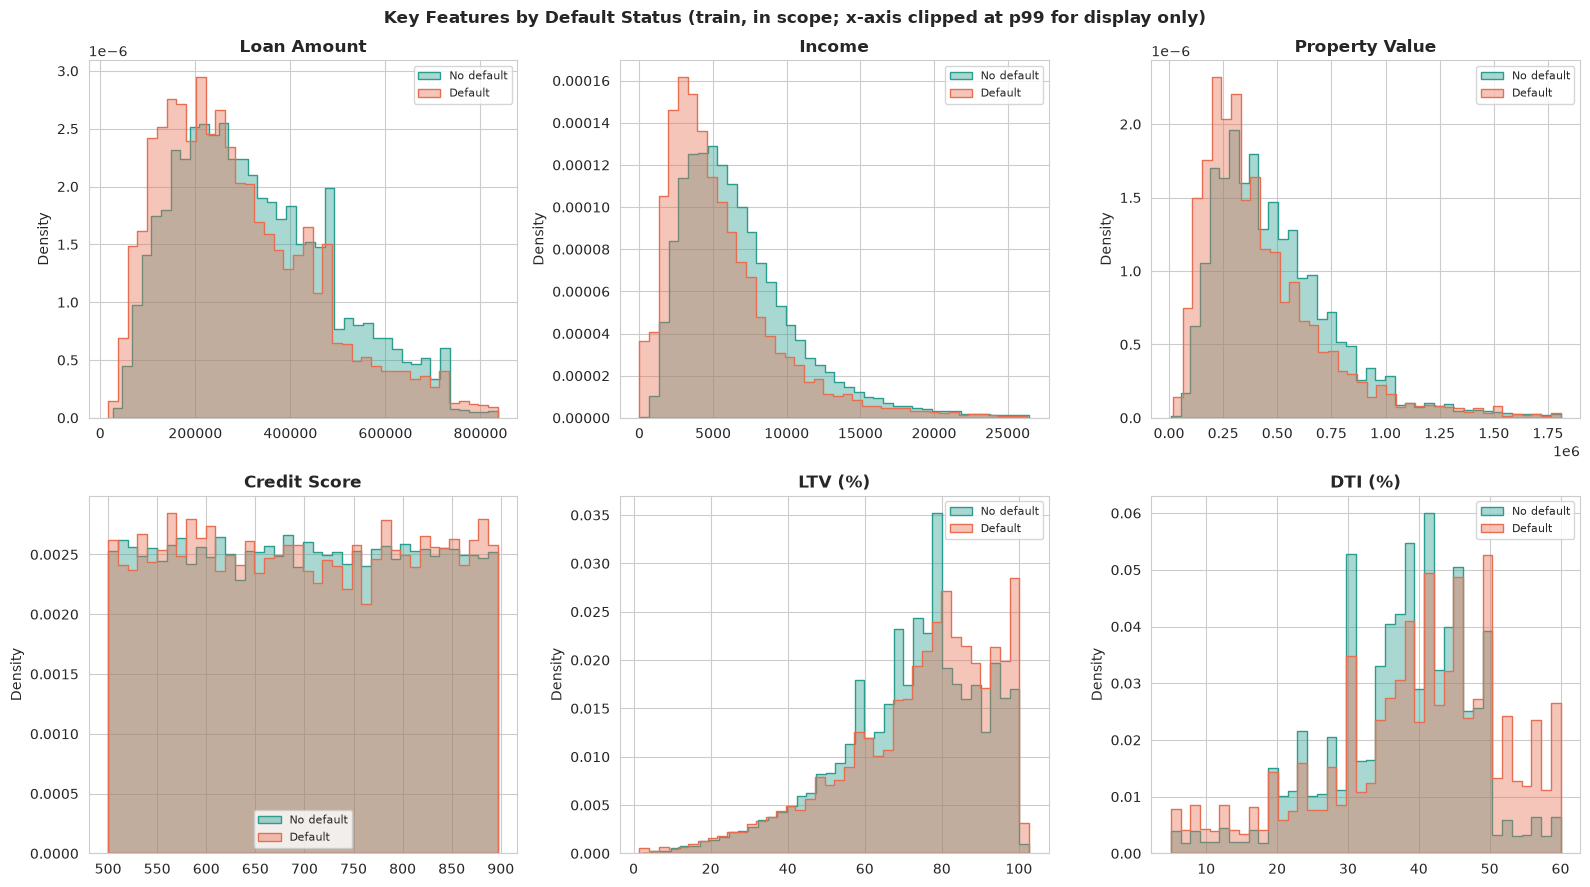

In [9]:
feats = [('loan_amount', 'Loan Amount'), ('income', 'Income'), ('property_value', 'Property Value'),
         ('Credit_Score', 'Credit Score'), ('LTV', 'LTV (%)'), ('dtir1', 'DTI (%)')]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (c, lab) in zip(axes.ravel(), feats):
    hi = eda[c].quantile(0.99)
    for s, col, nm in [(0, '#2a9d8f', 'No default'), (1, '#e76f51', 'Default')]:
        sns.histplot(eda.loc[(eda.Status == s) & (eda[c] <= hi), c], bins=40, stat='density',
                     element='step', fill=True, alpha=0.4, color=col, label=nm, ax=ax)
    ax.set_title(lab, fontweight='bold'); ax.set_xlabel(''); ax.legend(fontsize=8)
plt.suptitle('Key Features by Default Status (train, in scope; x-axis clipped at p99 for display only)',
             fontweight='bold')
plt.tight_layout(); plt.show()

**Reading the plots.** Without mean imputation, the narrow spikes in LTV and DTI that v0.1 showed are gone.
`Credit_Score` is still flat across both classes. The 300-month `term` bucket stands out, with a much higher
default rate than any other term.

## 6. Binning, WoE and Information Value (fitted on train)

Continuous features are cut into train quintiles plus an explicit `MISSING` bin. Categoricals keep their levels,
plus `MISSING`. WoE = ln(%good / %bad) uses 0.5 additive smoothing. IV is computed on **the same bins the model
uses**. v0.1 used separate deciles for IV, so the screen and the model did not see the same thing.

In [10]:
X_cols = list(train_s.columns)
NUM = [c for c in X_cols if pd.api.types.is_numeric_dtype(train_s[c]) and train_s[c].nunique() > 20]
CAT = [c for c in X_cols if c not in NUM]

def fit_edges(s, n=5):
    q = np.unique(np.quantile(s.dropna(), np.linspace(0, 1, n + 1)))
    q[0], q[-1] = -np.inf, np.inf
    return q

def to_bins(s, edges=None):
    if edges is None:
        return s.astype('object').where(s.notna(), 'MISSING').astype(str)
    return pd.cut(s, edges).astype(str).where(s.notna(), 'MISSING')

def woe_iv(b, y):
    t = pd.crosstab(b, y)
    good, bad = t[0] + 0.5, t[1] + 0.5
    dg, db = good / good.sum(), bad / bad.sum()
    w = np.log(dg / db)
    tab = pd.DataFrame({'n': t.sum(axis=1), 'default_rate': (t[1] / t.sum(axis=1)).round(4), 'woe': w.round(4)})
    return w.to_dict(), float(((dg - db) * w).sum()), tab

edges = {c: fit_edges(train_s[c]) for c in NUM}
edges.update({c: None for c in CAT})
WOE, IV, TABLES = {}, {}, {}
for c in X_cols:
    WOE[c], IV[c], TABLES[c] = woe_iv(to_bins(train_s[c], edges[c]), y_tr)

def transform(d, cols):
    # unseen categories -> WoE 0 (neutral)
    return pd.DataFrame({c: to_bins(d[c], edges[c]).map(WOE[c]).astype(float).fillna(0.0) for c in cols},
                        index=d.index)

W_tr, W_va, W_te = transform(train_s, X_cols), transform(val_s, X_cols), transform(test_s, X_cols)

iv = pd.Series(IV).sort_values(ascending=False)
band = pd.cut(iv, [-1, 0.02, 0.1, 0.3, 0.5, np.inf], labels=['useless', 'weak', 'medium', 'strong', 'SUSPICIOUS'])
iv_tab = pd.DataFrame({'IV': iv.round(4), 'band': band})
iv_tab

,IV,band
income,0.1748,medium
dtir1,0.1393,medium
lump_sum_payment,0.1355,medium
Neg_ammortization,0.1336,medium
submission_of_application,0.1298,medium
property_value,0.0880,weak
loan_type,0.0688,weak
business_or_commercial,0.0687,weak
LTV,0.0649,weak
Gender,0.0583,weak


## 7. Variable Selection

Three stages, each answering one audit finding:

1. **IV screen.** Drop IV < 0.02. Any IV > 0.5 stops the run: it means a leak got past §3.
2. **Redundancy screen (audit H3).** Among the survivors, taken in order of IV, drop any feature whose train WoE
   correlates |r| > 0.7 with a feature already kept. A correlation over all rows can miss two features that are
   blank on the *same* records (`dtir1` is debt ÷ `income`). If two features' blanks overlap ≥ 90% (Jaccard),
   the lower-IV feature's `MISSING` bin is set to WoE 0, so each blank counts once.
3. **Sign-constrained forward selection on validation (audits H2, M3).** At each step, add the candidate that
   most improves **validation** AUC, but only if every coefficient in the refitted model is negative. Under the
   WoE = ln(good/bad) convention, a positive coefficient reverses what the bins show. Stop when the gain falls
   below 0.002 AUC.

In [11]:
# 7.1 IV screen
suspicious = iv[iv > 0.5]
assert suspicious.empty, f'IV > 0.5 — investigate for leakage before modelling: {suspicious.to_dict()}'
pool = iv[iv >= 0.02].index.tolist()
print('IV >= 0.02:', pool)
print('dropped (IV < 0.02):', iv[iv < 0.02].index.tolist())

IV >= 0.02: ['income', 'dtir1', 'lump_sum_payment', 'Neg_ammortization', 'submission_of_application', 'property_value', 'loan_type', 'business_or_commercial', 'LTV', 'Gender', 'term', 'loan_amount', 'co-applicant_credit_type', 'age', 'loan_purpose']
dropped (IV < 0.02): ['Region', 'loan_limit', 'occupancy_type', 'approv_in_adv', 'Secured_by', 'Security_Type', 'construction_type', 'total_units', 'Credit_Worthiness', 'interest_only', 'Credit_Score', 'credit_type', 'open_credit']


In [12]:
# 7.2 redundancy screen
corr = W_tr[pool].corr()
kept, dropped_corr = [], []
for c in pool:  # pool is already ordered by IV, descending
    clash = [k for k in kept if abs(corr.loc[c, k]) > 0.7]
    if clash:
        dropped_corr.append((c, clash[0], round(corr.loc[c, clash[0]], 3)))
    else:
        kept.append(c)
print('dropped as redundant (feature, clashes with, r):', dropped_corr)

# shared blanks: a correlation over all rows can miss two features that are blank on the same records
# (dtir1 is derived from income). Count such a blank once: neutralise the lower-IV feature's MISSING bin.
MISS = {c: train_s[c].isna() for c in kept if train_s[c].isna().any()}
neutralised = []
for i, a in enumerate(kept):
    for b in kept[i + 1:]:
        if a in MISS and b in MISS:
            jac = (MISS[a] & MISS[b]).sum() / (MISS[a] | MISS[b]).sum()
            if jac >= 0.9 and WOE[b].get('MISSING', 0) != 0:
                neutralised.append((b, a, round(jac, 3), round(WOE[b]['MISSING'], 3)))
                WOE[b]['MISSING'] = 0.0
                TABLES[b].loc['MISSING', 'woe'] = 0.0
W_tr, W_va, W_te = transform(train_s, X_cols), transform(val_s, X_cols), transform(test_s, X_cols)
print('MISSING bin neutralised (feature, shares blanks with, Jaccard, old WoE):', neutralised)
print('candidates for selection:', kept)

dropped as redundant (feature, clashes with, r): [('business_or_commercial', 'loan_type', np.float64(0.999)), ('loan_amount', 'property_value', np.float64(0.798))]


MISSING bin neutralised (feature, shares blanks with, Jaccard, old WoE): [('dtir1', 'income', np.float64(0.988), 0.394)]
candidates for selection: ['income', 'dtir1', 'lump_sum_payment', 'Neg_ammortization', 'submission_of_application', 'property_value', 'loan_type', 'LTV', 'Gender', 'term', 'co-applicant_credit_type', 'age', 'loan_purpose']


In [13]:
# 7.3 sign-constrained forward selection, scored on validation
MIN_GAIN = 0.002

def fit_lr(cols):
    return LogisticRegression(max_iter=1000).fit(W_tr[cols], y_tr)

selected, best, log = [], 0.5, []
while True:
    trials = []
    for c in [k for k in kept if k not in selected]:
        m = fit_lr(selected + [c])
        sign_ok = bool((m.coef_[0] < 0).all())
        auc = roc_auc_score(y_va, m.predict_proba(W_va[selected + [c]])[:, 1])
        trials.append((auc, c, sign_ok))
    ok = [t for t in trials if t[2]]
    if not ok:
        break
    auc, c, _ = max(ok)
    if auc - best < MIN_GAIN:
        break
    rejected = [t[1] for t in trials if not t[2] and t[0] > auc]
    selected.append(c)
    log.append({'step': len(selected), 'added': c, 'val_AUC': round(auc, 4), 'gain': round(auc - best, 4),
                'better_but_sign_reversed': ', '.join(rejected)})
    best = auc

sel_log = pd.DataFrame(log)
sel_log

,step,added,val_AUC,gain,better_but_sign_reversed
0,1,income,0.5957,0.0957,
1,2,LTV,0.6290,0.0333,
2,3,Neg_ammortization,0.6547,0.0256,
3,4,lump_sum_payment,0.6814,0.0268,
4,5,dtir1,0.6996,0.0182,
5,6,submission_of_application,0.7138,0.0142,
6,7,co-applicant_credit_type,0.7166,0.0028,
7,8,loan_type,0.7188,0.0022,


In [14]:
full = fit_lr(kept)
print(f'all {len(kept)} candidates (unconstrained): val AUC = '
      f'{roc_auc_score(y_va, full.predict_proba(W_va[kept])[:, 1]):.4f}; '
      f'positive coefs: {[c for c, b in zip(kept, full.coef_[0]) if b > 0]}')
print(f'selected {len(selected)} features: val AUC = {best:.4f}')
print('selected:', selected)

all 13 candidates (unconstrained): val AUC = 0.7220; positive coefs: ['property_value']
selected 8 features: val AUC = 0.7188
selected: ['income', 'LTV', 'Neg_ammortization', 'lump_sum_payment', 'dtir1', 'submission_of_application', 'co-applicant_credit_type', 'loan_type']


## 8. Final Model — WoE Logistic Regression (fit on train)

In [15]:
lr = fit_lr(selected)
coef = pd.Series(lr.coef_[0], index=selected)
assert (coef < 0).all(), 'sign constraint violated'
print('intercept:', round(lr.intercept_[0], 4))
print(coef.round(4).sort_values().to_string())
for c in selected:
    print(f'\n[{c}]  IV={IV[c]:.4f}')
    print(TABLES[c].to_string())

intercept: -1.6801
lump_sum_payment            -1.0801
Neg_ammortization           -1.0085
LTV                         -0.8739
dtir1                       -0.7846
submission_of_application   -0.7754
income                      -0.6544
co-applicant_credit_type    -0.4715
loan_type                   -0.3319

[income]  IV=0.1748
                      n  default_rate     woe
income                                       
(-inf, 3360.0]    14931        0.2757 -0.6940
(3360.0, 4980.0]  15375        0.1713 -0.0833
(4980.0, 6720.0]  14489        0.1370  0.1803
(6720.0, 9420.0]  15001        0.1157  0.3740
(9420.0, inf]     14782        0.1147  0.3831
MISSING            5420        0.1133  0.3970

[LTV]  IV=0.0649
                      n  default_rate     woe
LTV                                          
(-inf, 57.586]    16011        0.1470  0.0985
(57.586, 70.397]  16008        0.1209  0.3233
(70.397, 79.287]  15990        0.1365  0.1848
(79.287, 89.226]  16036        0.1741 -0.1033
(89.226, i

## 9. Scorecard Points (PDO scaling)
600 points at 50:1 odds, 20 points to double the odds (PDO = 20):
`points = -(coef·WoE + intercept/n)·factor + offset/n`.

In [16]:
PDO, base, base_odds = 20, 600, 50
factor = PDO / np.log(2); offset = base - factor * np.log(base_odds)
n = len(selected); b0 = lr.intercept_[0]
rows = [{'feature': f, 'bin': b, 'woe': round(w, 3),
         'points': int(round(-(coef[f] * w + b0 / n) * factor + offset / n))}
        for f in selected for b, w in WOE[f].items()]
scorecard = pd.DataFrame(rows)
spread = scorecard.groupby('feature')['points'].agg(['min', 'max'])
spread['range'] = spread['max'] - spread['min']
print(f'factor={factor:.2f} offset={offset:.2f}')
print(spread.sort_values('range', ascending=False).to_string())
print('\nlargest |WoE| in any scored bin:', scorecard.woe.abs().max(), '(v0.1: 10.9)')

factor=28.85 offset=487.12
                           min  max  range
feature                                   
lump_sum_payment            -2   69     71
Neg_ammortization           39   71     32
dtir1                       52   75     23
income                      54   74     20
LTV                         57   75     18
submission_of_application   62   79     17
loan_type                   61   68      7
co-applicant_credit_type    65   70      5

largest |WoE| in any scored bin: 2.224 (v0.1: 10.9)


In [17]:
scorecard

,feature,bin,woe,points
0,income,"(-inf, 3360.0]",-0.694,54
1,income,"(3360.0, 4980.0]",-0.083,65
2,income,"(4980.0, 6720.0]",0.180,70
3,income,"(6720.0, 9420.0]",0.374,74
4,income,"(9420.0, inf]",0.383,74
5,income,MISSING,0.397,74
6,LTV,"(-inf, 57.586]",0.098,69
7,LTV,"(57.586, 70.397]",0.323,75
8,LTV,"(70.397, 79.287]",0.185,72
9,LTV,"(79.287, 89.226]",-0.103,64


## 10. Evaluation — AUC, Gini, KS (with 95% bootstrap CIs), Calibration

In [18]:
def metrics(y, p):
    auc = roc_auc_score(y, p); fpr, tpr, _ = roc_curve(y, p)
    return auc, 2 * auc - 1, float(np.max(tpr - fpr))

def bootstrap_ci(y, p, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); y = np.asarray(y); stats = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        stats.append(metrics(y[i], p[i]))
    return np.percentile(np.array(stats), [2.5, 97.5], axis=0)

p_va = lr.predict_proba(W_va[selected])[:, 1]
p_te = lr.predict_proba(W_te[selected])[:, 1]
res = []
for nm, y, p in [('validation', y_va, p_va), ('test', y_te, p_te)]:
    m = metrics(y, p); lo, hi = bootstrap_ci(y, p)
    res.append({'set': nm, 'n': len(y),
                **{k: f'{v:.3f} [{a:.3f}, {b:.3f}]' for k, v, a, b in zip(['AUC', 'Gini', 'KS'], m, lo, hi)}})
results = pd.DataFrame(res).set_index('set')
results

,n,AUC,Gini,KS
set,,,,
validation,26721,"0.719 [0.711, 0.727]","0.438 [0.421, 0.455]","0.323 [0.310, 0.339]"
test,26651,"0.726 [0.718, 0.734]","0.452 [0.437, 0.469]","0.326 [0.315, 0.345]"


In [19]:
cal = pd.DataFrame({'p': p_te, 'y': y_te.values})
cal['decile'] = pd.qcut(cal.p.rank(method='first'), 10, labels=False) + 1
cal = cal.groupby('decile').agg(pred=('p', 'mean'), obs=('y', 'mean'), n=('y', 'size'))
cal['gap'] = cal.obs - cal.pred
print(cal.round(4).to_string())
print(f'\nmax |gap| = {cal.gap.abs().max():.4f} | share of test scored PD > 0.99: {(p_te > 0.99).mean():.4f} (v0.1: 0.101)')

          pred     obs     n     gap
decile                              
1       0.0481  0.0368  2666 -0.0114
2       0.0649  0.0544  2665 -0.0105
3       0.0824  0.0713  2665 -0.0111
4       0.0971  0.1021  2665  0.0049
5       0.1121  0.1144  2665  0.0024
6       0.1319  0.1456  2665  0.0137
7       0.1585  0.1595  2665  0.0010
8       0.1909  0.2173  2665  0.0263
9       0.2568  0.2570  2665  0.0003
10      0.4467  0.4349  2665 -0.0118

max |gap| = 0.0263 | share of test scored PD > 0.99: 0.0000 (v0.1: 0.101)


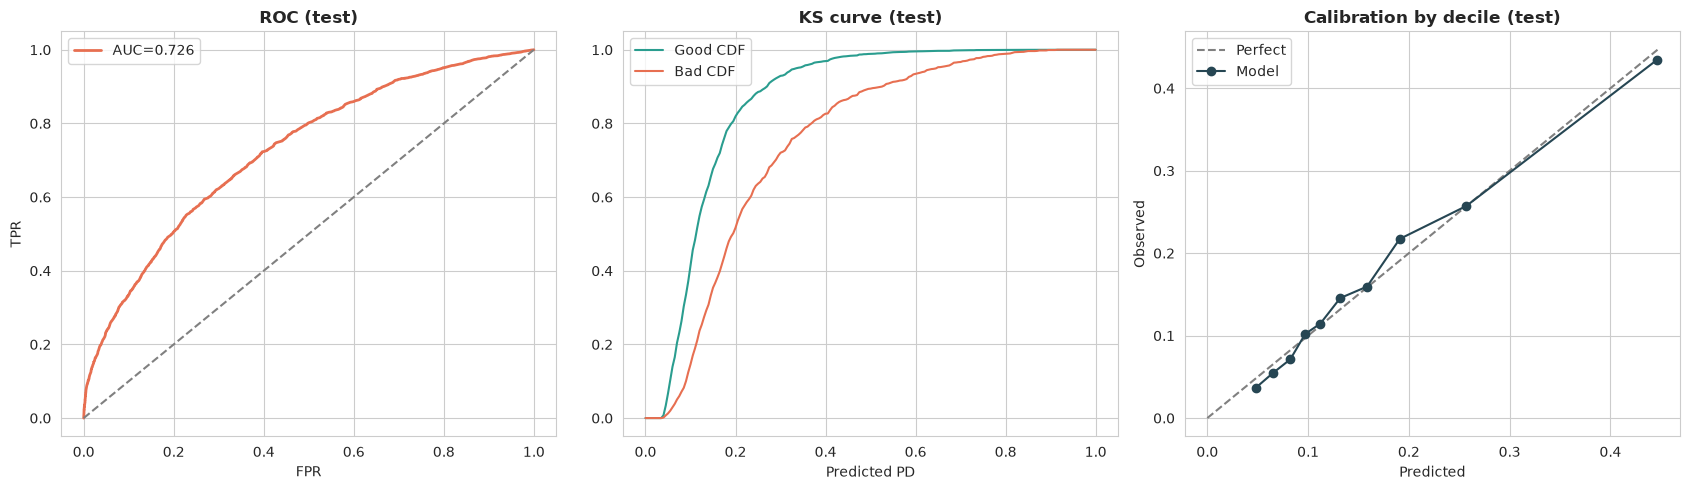

In [20]:
fpr, tpr, _ = roc_curve(y_te, p_te)
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].plot(fpr, tpr, color='#e76f51', lw=2, label=f'AUC={roc_auc_score(y_te, p_te):.3f}')
ax[0].plot([0, 1], [0, 1], '--', color='gray'); ax[0].set_title('ROC (test)', fontweight='bold')
ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend()
thr = np.linspace(0, 1, 201)
ax[1].plot(thr, [np.mean(p_te[y_te.values == 0] <= t) for t in thr], color='#2a9d8f', label='Good CDF')
ax[1].plot(thr, [np.mean(p_te[y_te.values == 1] <= t) for t in thr], color='#e76f51', label='Bad CDF')
ax[1].set_title('KS curve (test)', fontweight='bold'); ax[1].set_xlabel('Predicted PD'); ax[1].legend()
ax[2].plot([0, cal.pred.max()], [0, cal.pred.max()], '--', color='gray', label='Perfect')
ax[2].plot(cal.pred, cal.obs, 'o-', color='#264653', label='Model')
ax[2].set_title('Calibration by decile (test)', fontweight='bold')
ax[2].set_xlabel('Predicted'); ax[2].set_ylabel('Observed'); ax[2].legend()
plt.tight_layout(); plt.show()

## 11. Comparison with v0.1 and Conclusion

In [21]:
t = results.loc['test']
comparison = pd.DataFrame({
    'v0.1 (audited)': ['all rows incl. blank-field proxies', '12 (IV on full data, no sign check)',
                       '0.822', '0.644', '0.500', '10.1%', '3 (loan_amount, LTV, co-applicant)'],
    'v0.2 (this notebook)': ['complete applications only', f'{len(selected)} (train IV + redundancy + signed forward selection)',
                             t.AUC, t.Gini, t.KS, f'{(p_te > 0.99).mean():.1%}', '0'],
}, index=['population', 'features', 'test AUC', 'test Gini', 'test KS', 'test share PD > 0.99', 'reversed-sign coefs'])
comparison

,v0.1 (audited),v0.2 (this notebook)
population,all rows incl. blank-field proxies,complete applications only
features,"12 (IV on full data, no sign check)",8 (train IV + redundancy + signed forward sele...
test AUC,0.822,"0.726 [0.718, 0.734]"
test Gini,0.644,"0.452 [0.437, 0.469]"
test KS,0.500,"0.326 [0.315, 0.345]"
test share PD > 0.99,10.1%,0.0%
reversed-sign coefs,"3 (loan_amount, LTV, co-applicant)",0


**Reading the results.**

- The v0.1 headline (AUC 0.82) was inflated by records the model could score as certain defaults from blank
  fields alone. Once those records are routed out, the model no longer produces a PD ≈ 1 block, and its
  largest WoE is a plausible size.
- Every coefficient has the correct sign, the duplicate `loan_type` / `business_or_commercial` pair is resolved,
  and the validation set earns its place by choosing the variables.
- Calibration holds within the in-scope population, so the output can be read as a probability *of the target
  as defined*.

**Status:** methodologically sound pipeline, **not validated for credit use.** §3.3 shows that in the scored
population the target matches "interest rate never recorded" exactly. Until a dataset with a genuine repayment
outcome (and ideally a second vintage for out-of-time testing) is available, these metrics describe how well
application characteristics predict that data-collection artifact, not borrower credit risk.